# fMRI 인코더 학습과 HCP 19개 과제 분류

HCP β-map을 입력으로 받아 19개 과제 조건을 분류하는 1D CNN을 학습했다. 분류 성능을 확인한 뒤 인코더 가중치를 저장해 NSD 캡션 생성에 재사용한다.

## 이 노트북에서 확인할 내용

1. β-map 벡터를 고정 길이 입력으로 변환하는 방법
2. 768차원 특징을 만드는 인코더와 분류 헤드
3. 학습 곡선, test Macro-F1, confusion matrix와 특징 시각화
4. 직접 전처리한 HCP 데이터의 추가 입력 결과

**주 학습에는 01 노트북의 산출물이 아니라 수업에서 제공한 HCP β-map을 사용했다.** 원시 전처리 실습과 분류 학습은 별도 데이터 흐름이다.

## 실행 전 확인

Google Colab과 Google Drive 경로를 사용한다. 제공 NPZ 파일을 `HCP_data`에 준비하고 Drive 경로를 맞춰야 한다. 마지막 추가 입력 셀에는 01 노트북의 산출물도 필요하다. 아래 그림과 수치는 당시 실행 결과를 보존한 것으로, 이번 정리에서 모델을 다시 학습하지 않았다.


In [1]:
!pip install nilearn nibabel
!pip install antspyx
!pip install transformers evaluate rouge_score h5py


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 73.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.4/22.4 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 12.6 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.3 MB/s eta 0:00:00
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=41ef39ddb0b2ff9dfbf3ca9807a7fb7c26ca1e2bde9ea34bf9d8114e7cb46715
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
Successfully built rouge_score


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path
import importlib.util
import nibabel as nib
from nilearn import image, plotting
from nilearn import datasets
from nilearn.maskers import NiftiMasker
from nilearn.glm.first_level import (
        FirstLevelModel,
        make_first_level_design_matrix,
    )
from nilearn.masking import apply_mask
from sklearn.model_selection import train_test_split
from scipy.spatial.transform import Rotation
import ants
import random
import json

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.manifold import TSNE
from transformers import AutoTokenizer, AutoModelForCausalLM
import evaluate
import h5py
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer


## 1. 분류 데이터와 실험 구성

제공된 NPZ의 `betas`에서 `assignment19_indices`에 해당하는 map을 선택한다. `rest`를 제외한 조건은 다음과 같다.

```text
fear, neut, loss, win, math, story,
lf, lh, rf, rh, t, match, relation,
mental, rnd, body, faces, places, tools
```

파일마다 위 순서로 19개 map이 정렬되어 있다는 전제로 라벨을 `0~18`로 부여한다. 입력 벡터 길이는 `AdaptiveAvgPool1d(100000)`으로 통일한다. 이 연산은 벡터를 일정 길이로 맞추는 처리이며, 다른 데이터셋 사이의 해부학적 voxel 대응을 만드는 단계는 아니다.

| 항목 | 실행 기록 |
|---|---|
| 전체 입력 | `(1520, 100000)` |
| 클래스 수 | 19 |
| train / validation / test | 80% / 10% / 10% |
| 분할 방식 | 샘플 단위 무작위 분할, `random_state=42` |
| batch size | 64 |

피험자별 분할은 적용하지 않았다. 아래 test 점수는 이 분할 안에서의 분류 결과다.


## 2. 인코더와 분류 헤드

```text
β-map: 100,000
 → Conv1d 블록 × 4
 → AdaptiveAvgPool1d(256)
 → Flatten: 8,192
 → FC: 1,024 → 768
 → ReLU + Linear: 768 → 19
```

각 convolution 블록은 BatchNorm, GELU, dropout, max pooling을 포함한다. 채널은 `1 → 32 → 64 → 64 → 32`, kernel size는 `128 → 64 → 32 → 16`이다. convolution 블록의 dropout은 0.1, FC 내부 dropout은 0.3이다. 클래스 정의의 기본 특징 차원은 256이지만 **실제 학습에서는 768을 지정**한다.

분류 헤드는 인코더와 분리했다. 후속 캡션 생성에서는 19개 클래스 점수 대신 768차원 특징을 사용하기 때문이다. 헤드는 logits를 반환하고 `CrossEntropyLoss`로 학습한다.

### 설계 변경 과정

초기 MLP에서 학습 수렴이 충분하지 않아 1D CNN으로 변경했다. 이후 캡션 생성에 연결하는 과정에서 특징 차원을 256에서 768로 늘리고, convolution 블록을 4개로 확장했다. GELU와 dropout도 도입했다. 이는 당시 반복 실험을 정리한 변경 이력이며, 각 설정의 효과를 분리한 비교 점수는 남아 있지 않다.

### 학습과 결과를 읽는 순서

아래 셀은 Drive 연결 → 모델 정의 → 데이터 로딩 → 학습 → 평가 → 추가 입력 테스트 순서다.

| 학습 항목 | 설정 |
|---|---|
| Optimizer | Adam |
| Learning rate | `1e-4` |
| Weight decay | `1e-5` |
| Epochs | 35 |
| 저장 대상 | 최종 인코더 `state_dict` |

**기록된 test Macro-F1은 0.8667**이다. confusion matrix는 조건별 오분류를 보여주며, 행·열의 숫자는 앞의 조건 순서에 대응한다.

출력된 validation loss는 15 epoch에서 0.4836, 최종 35 epoch에서 0.5422다. 학습 후반에는 train loss가 더 낮아져도 validation loss가 개선되지 않았다. 현재 결과는 validation 최적 체크포인트가 아니라 마지막 epoch 모델 기준이다.

특징의 t-SNE는 test 특징을 2차원으로 투영한 보조 그림이다. `perplexity=1`을 사용했으므로 배치 모양 자체를 클래스 분리 성능으로 해석하지는 않는다.

학습 후 `fmri_encoder_weights.pth`를 저장하고 04 노트북에서 불러온다.


In [3]:
from google.colab import drive

drive.mount('/content/drive')

drive_url = f"/content/drive/MyDrive"


Mounted at /content/drive


In [4]:

class fMRIEncoder(nn.Module):
    def __init__(self, input_dim=100000, feature_dim=256):
        super(fMRIEncoder, self).__init__()

        self.latent_dim = feature_dim

        self.feature_extractor = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=32, kernel_size=128, stride=2, padding=128),
            nn.BatchNorm1d(32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=64, stride=2, padding=64),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.MaxPool1d(kernel_size=4),

            nn.Conv1d(in_channels=64, out_channels=64, kernel_size=32, stride=2, padding=32),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.MaxPool1d(kernel_size=4),

            nn.Conv1d(in_channels=64, out_channels=32, kernel_size=16, stride=2, padding=16),
            nn.BatchNorm1d(32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.MaxPool1d(kernel_size=2),
        )

        self.global_pool = nn.AdaptiveAvgPool1d(256)

        self.fc_layer = nn.Sequential(
            nn.Linear(32 * 256, 1024),
            nn.BatchNorm1d(1024),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(1024, feature_dim)
        )

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(1)

        x = self.feature_extractor(x)
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        output = self.fc_layer(x)
        return output

class HCPClassifier(nn.Module):
    def __init__(self, encoder, num_classes=19):
        super(HCPClassifier, self).__init__()
        self.encoder = encoder
        self.head = nn.Sequential(
            nn.ReLU(),
            nn.Linear(encoder.latent_dim, num_classes)
        )

    def forward(self, x):
        features = self.encoder(x)
        logits = self.head(features)
        return logits, features


In [8]:

max_file = 100

adaptive_pool = nn.AdaptiveAvgPool1d(100000)

X_list, y_list = [], []
for idx, HCP_betamaps in enumerate(os.listdir(f"{drive_url}/HCP_data")):
    if idx >= max_file:
        break

    data = np.load(f"{drive_url}/HCP_data/{HCP_betamaps}", allow_pickle=True)

    print(f"{idx+1}st DataSet Columns:", data.files)
    print("Labels:", data['assignment19_labels'])

    compressed_list = []
    for data in data['betas'][data['assignment19_indices']] :
        tensor_data = torch.FloatTensor(data).unsqueeze(0).unsqueeze(0)
        pooled_data = adaptive_pool(tensor_data)
        compressed_list.append(pooled_data.squeeze().numpy())

    X_list.append(np.array(compressed_list))
    y_list.append(np.arange(19))

    print("Betas shape:", X_list[idx].shape)
    print("Labels contents with shape:", y_list, y_list[idx].shape)

X = np.vstack(X_list)
y = np.concatenate(y_list)
print("Integrated Betas shape:", X.shape)
print("Integrated Labels contents with shape:", y, y.shape)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

batch_size = 64
train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val), torch.tensor(y_val)), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test), torch.tensor(y_test)), batch_size=batch_size, shuffle=False)


1st DataSet Columns: ['betas', 'contrast_labels', 'tasks', 'contrast_names', 'cope_indices', 'subject', 'map_name', 'feat_suffix', 'assignment19_indices', 'assignment19_labels', 'requested_20_classes', 'unavailable_classes']
Labels: ['fear' 'neut' 'loss' 'win' 'math' 'story' 'lf' 'lh' 'rf' 'rh' 't' 'match'
 'relation' 'mental' 'rnd' 'body' 'faces' 'places' 'tools']
Betas shape: (19, 100000)
Labels contents with shape: [array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18])] (19,)
2st DataSet Columns: ['betas', 'contrast_labels', 'tasks', 'contrast_names', 'cope_indices', 'subject', 'map_name', 'feat_suffix', 'assignment19_indices', 'assignment19_labels', 'requested_20_classes', 'unavailable_classes']
Labels: ['fear' 'neut' 'loss' 'win' 'math' 'story' 'lf' 'lh' 'rf' 'rh' 't' 'match'
 'relation' 'mental' 'rnd' 'body' 'faces' 'places' 'tools']
Betas shape: (19, 100000)
Labels contents with shape: [array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 1

Epoch 5/35 - Train Loss: 0.3713, Val Loss: 0.6386
Epoch 10/35 - Train Loss: 0.0646, Val Loss: 0.5508
Epoch 15/35 - Train Loss: 0.0155, Val Loss: 0.4836
Epoch 20/35 - Train Loss: 0.0070, Val Loss: 0.5054
Epoch 25/35 - Train Loss: 0.0046, Val Loss: 0.5241
Epoch 30/35 - Train Loss: 0.0031, Val Loss: 0.5308
Epoch 35/35 - Train Loss: 0.0020, Val Loss: 0.5422


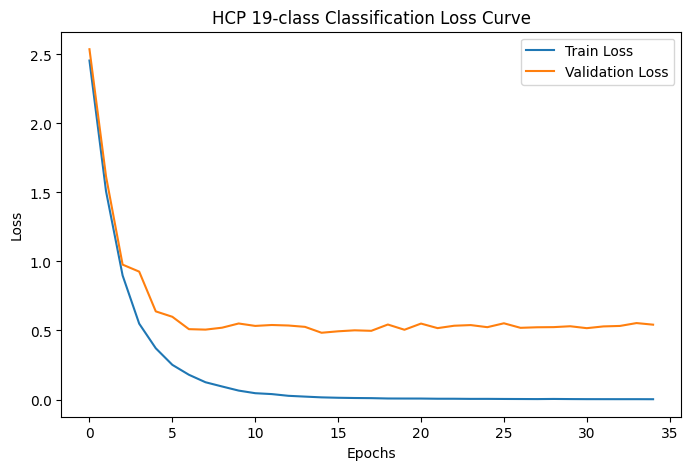

In [10]:


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
feature_dim = 768
criterion = nn.CrossEntropyLoss()
epochs = 35

encoder = fMRIEncoder(input_dim=X.shape[1], feature_dim=feature_dim)
model = HCPClassifier(encoder, num_classes=19).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5)

train_losses, val_losses = [], []

for epoch in range(epochs):

    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()

        logits, _ = model(inputs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
    train_losses.append(running_loss / len(train_loader.dataset))

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            logits, _ = model(inputs)
            loss = criterion(logits, labels)
            val_loss += loss.item() * inputs.size(0)
    val_losses.append(val_loss / len(val_loader.dataset))

    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('HCP 19-class Classification Loss Curve')
plt.legend()
plt.show()


Test Macro-F1 Score: 0.8667


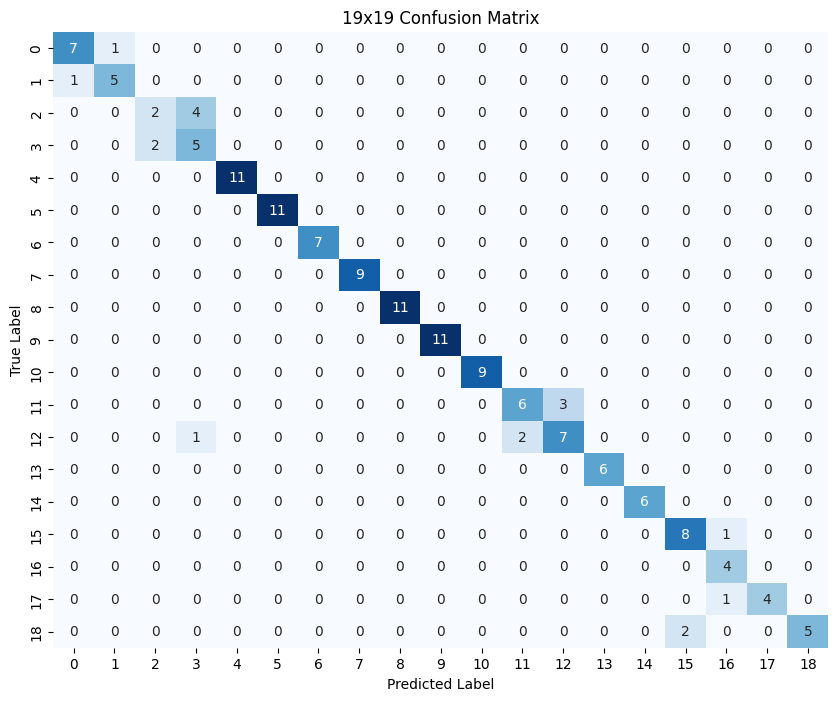

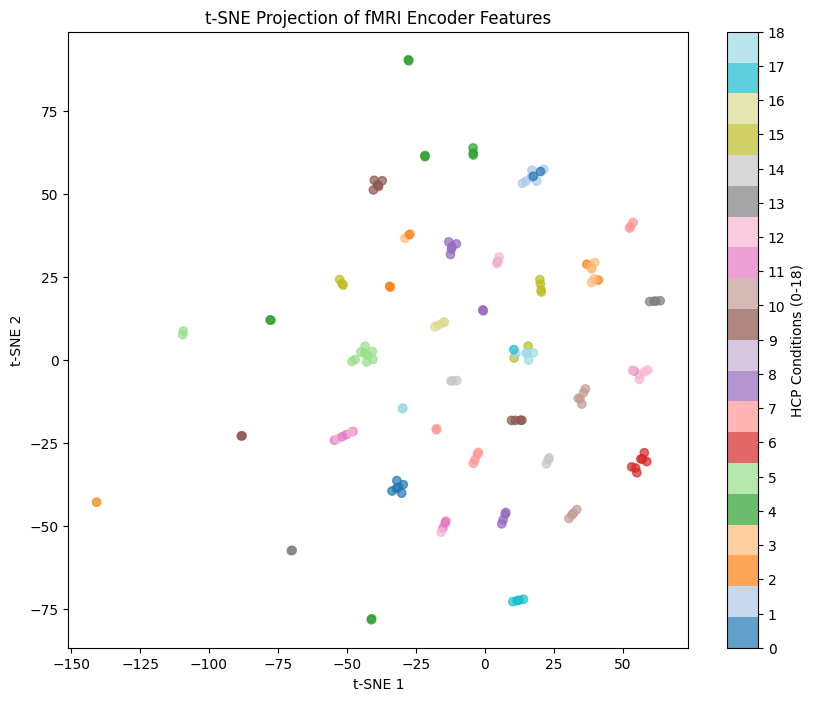

In [11]:


model.eval()
all_preds, all_labels, all_features = [], [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        logits, features = model(inputs)
        preds = torch.argmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_features.extend(features.cpu().numpy())

macro_f1 = f1_score(all_labels, all_preds, average='macro')
print(f"Test Macro-F1 Score: {macro_f1:.4f}")

cm = confusion_matrix(all_labels, all_preds, labels=np.arange(19))

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('19x19 Confusion Matrix')
plt.show()

tsne = TSNE(n_components=2, random_state=42, perplexity=1)
tsne_results = tsne.fit_transform(np.array(all_features))

plt.figure(figsize=(10, 8))
scatter = plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=all_labels, cmap='tab20', alpha=0.7)
plt.colorbar(scatter, ticks=range(19), label='HCP Conditions (0-18)')
plt.title('t-SNE Projection of fMRI Encoder Features')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

torch.save(model.encoder.state_dict(), f"{drive_url}/fmri_encoder_weights.pth")


/tmp/ipykernel_1074/1445609658.py:25: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  logits, features = model(torch.FloatTensor(compressed_list).to(device))


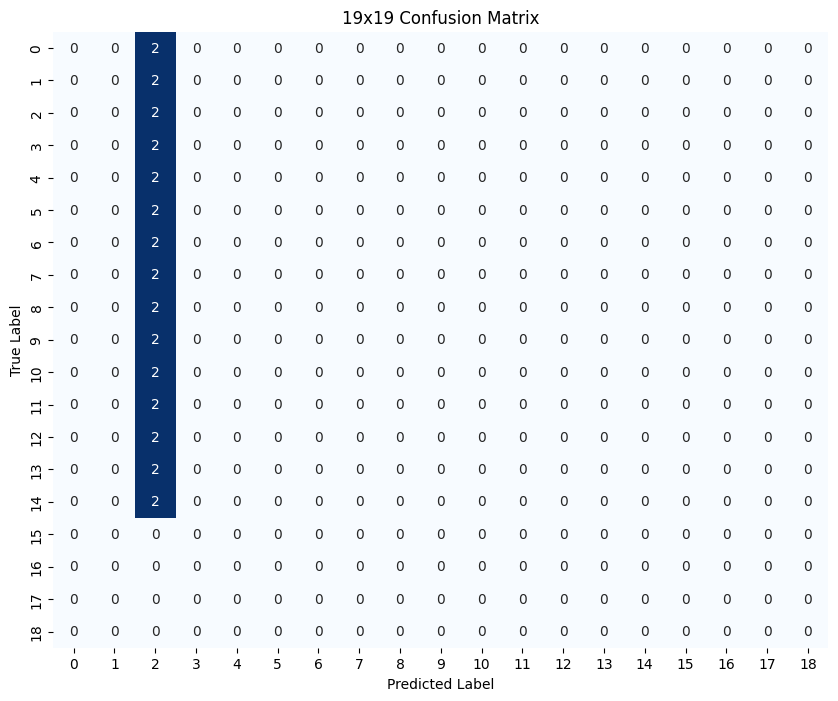

In [12]:
data = np.load(f"{drive_url}/HCP_data/100206_hcp_full_betamaps_pe1_hp200_s2_level2_86contrast.npz", allow_pickle=True)

idx_to_label = data['assignment19_labels']

label_to_idx = {}
for idx, label in enumerate(idx_to_label) :
    label_to_idx[label]=idx

data = np.load(f"{drive_url}/preprocessed data/HCP_preprocessed/HCP_100206_data.npz", allow_pickle=True)

idxs = []
for label in data['labels']:
    idxs.append(label_to_idx[label])

adaptive_pool = nn.AdaptiveAvgPool1d(100000)

compressed_list = []

for data in data['data']:
    tensor_data = torch.FloatTensor(data).unsqueeze(0).unsqueeze(0)
    pooled_data = adaptive_pool(tensor_data)
    compressed_list.append(pooled_data.squeeze().numpy())

with torch.no_grad():
    logits, features = model(torch.FloatTensor(compressed_list).to(device))
    preds = torch.argmax(logits, dim=1)

cm = confusion_matrix(idxs, preds.cpu(), labels=np.arange(19))

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('19x19 Confusion Matrix')
plt.show()


## 3. 직접 전처리한 HCP 데이터의 추가 입력 결과

마지막 셀은 01 노트북에서 만든 `HCP_100206_data.npz`를 학습된 분류기에 넣은 결과다. 제공 데이터의 라벨 순서를 기준으로 조건명을 정수 라벨로 바꾸고, β-map 길이를 100,000으로 맞춘 뒤 추론한다.

기존 실행에서는 예측이 한 클래스에 집중되는 현상이 나타났다. 주 학습 데이터와 직접 전처리 데이터는 공간 정합, 마스크, 처리 설정이 같다고 보장되지 않는다. 길이를 맞추는 pooling만으로 이러한 차이가 해소되지는 않는다.

이 결과는 별도 입력에 대한 진단 실험으로, 앞의 test Macro-F1과 구분해서 읽는다. 특정 전처리 단계 하나를 실패 원인으로 확정하는 비교 실험은 하지 않았다.

## 정리

제공된 HCP β-map으로 768차원 인코더를 학습하고, 샘플 단위 분할에서 Macro-F1 0.8667을 기록했다. 다음 단계에서는 분류 헤드를 제거하고 인코더를 NSD 캡션 생성 모델의 입력 특징 추출기로 사용한다.
